## LIBRERÍAS GENERAL

In [ ]:
# =========================================================
# Librerias que vamos a usar
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                               accuracy_score, f1_score, confusion_matrix,
                               classification_report)
# Estilo de las graficas (colores y tamanio por defecto)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["font.size"] = 11

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
AZUL = "#264653"
GRIS = "#808080"
# Para ver bien las tablas
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Librerias cargadas correctamente")

Librerias cargadas correctamente


## LIMPIEZA GENERAL

In [ ]:
# =====================================================================
# LIMPIEZA DEFINITIVA DE LOS ARCHIVOS EVA (2007-2018 y 2019-2025)
# Resultado: la tabla "datos" con UNA fila por municipio + cultivo +
# estado fisico + anio, lista para entrenar los modelos.
# =====================================================================

import pandas as pd
import numpy as np

# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto: los numeros vienen en formato colombiano
# ("1.247.206,27") y los codigos DANE tienen ceros a la izquierda ("05001").
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
# =========================================================
print("PASO 2: Dejar solo las columnas necesarias, con el mismo nombre")

# El archivo viejo trae saltos de linea dentro de los nombres
# ("Área Sembrada\n(ha)"): los cambiamos por un espacio.
eva_viejo.columns = [" ".join(nombre.split()) for nombre in eva_viejo.columns]
eva_nuevo.columns = [" ".join(nombre.split()) for nombre in eva_nuevo.columns]

# Solo columnas que existen en LOS DOS archivos y que se usan despues.
# (El rendimiento no se carga: se recalcula al final con la formula.)
nombres_nuevo = {
    "Código Dane departamento":  "cod_dep",
    "Departamento":              "departamento",
    "Código Dane municipio":     "cod_mun",
    "Municipio":                 "municipio",
    "Grupo cultivo":             "grupo",
    "Cultivo":                   "cultivo",
    "Desagregación cultivo":     "desagregacion",
    "Año":                       "anio",
    "Periodo":                   "periodo",
    "Área sembrada":             "area_sembrada",
    "Área cosechada":            "area_cosechada",
    "Producción":                "produccion",
    "Ciclo del cultivo":         "ciclo",
    "Estado físico del cultivo": "estado_fisico",
}
nombres_viejo = {
    "CÓD. DEP.":                                     "cod_dep",
    "DEPARTAMENTO":                                  "departamento",
    "CÓD. MUN.":                                     "cod_mun",
    "MUNICIPIO":                                     "municipio",
    "GRUPO DE CULTIVO":                              "grupo",
    "CULTIVO":                                       "cultivo",
    "DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO": "desagregacion",
    "AÑO":                                           "anio",
    "PERIODO":                                       "periodo",
    "Área Sembrada (ha)":                            "area_sembrada",
    "Área Cosechada (ha)":                           "area_cosechada",
    "Producción (t)":                                "produccion",
    "CICLO DE CULTIVO":                              "ciclo",
    "ESTADO FISICO PRODUCCION":                      "estado_fisico",
}
COLUMNAS = list(nombres_nuevo.values())
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)[COLUMNAS].copy()
eva_viejo = eva_viejo.rename(columns=nombres_viejo)[COLUMNAS].copy()

print("Columnas que se conservan:", COLUMNAS)
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Convertir los numeros y los codigos DANE
# =========================================================
print("PASO 3: Convertir los numeros y los codigos DANE")

def convertir_a_numero(columna):
    # "1.247.206,27" -> 1247206.27  (el punto separa miles, la coma es decimal)
    texto = columna.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

for df in (eva_viejo, eva_nuevo):
    for columna in ["anio", "area_sembrada", "area_cosechada", "produccion"]:
        df[columna] = convertir_a_numero(df[columna])
    df["anio"] = df["anio"].astype(int)
    # Codigos: "15.114" -> "15114"  y  "5.001" -> "05001"
    df["cod_dep"] = df["cod_dep"].str.replace(".", "", regex=False).str.zfill(2)
    df["cod_mun"] = df["cod_mun"].str.replace(".", "", regex=False).str.zfill(5)

# Controles: ningun numero vacio, ningun negativo, codigos coherentes
for nombre, df in [("2007-2018", eva_viejo), ("2019-2025", eva_nuevo)]:
    numeros = df[["area_sembrada", "area_cosechada", "produccion"]]
    assert numeros.notna().all().all(), "Hay numeros que no se pudieron convertir en " + nombre
    assert (numeros >= 0).all().all(), "Hay numeros negativos en " + nombre
    assert (df["cod_mun"].str[:2] == df["cod_dep"]).all(), "Codigos inconsistentes en " + nombre

print("PASO 3: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto.str.replace(r"\s+", " ", regex=True)   # espacios dobles -> uno

for df in (eva_viejo, eva_nuevo):
    for columna in ["departamento", "municipio", "grupo", "cultivo",
                    "desagregacion", "ciclo", "estado_fisico"]:
        df[columna] = limpiar_texto(df[columna])

print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 5: Estandarizar los nombres de cultivo y de estado fisico
# =========================================================
# Regla: solo se unifica lo que es el MISMO cultivo. Lo que es distinto
# se deja separado, y si queda solo en un archivo se elimina en el PASO 6.
print("PASO 5: Estandarizar los nombres de cultivo y de estado fisico")

# 5.1 El archivo nuevo junta las tres canas en "CANA", pero la desagregacion
#     las separa. Como son productos distintos, las separamos igual que el viejo.
es_cana = eva_nuevo["cultivo"] == "CANA"
eva_nuevo.loc[es_cana, "cultivo"] = eva_nuevo.loc[es_cana, "desagregacion"]
eva_nuevo["cultivo"] = eva_nuevo["cultivo"].replace({"CANA DE AZUCAR": "CANA AZUCARERA",
                                                     "ESTEVIA": "STEVIA"})

# 5.2 Nombres del archivo viejo que se pasan al nombre del archivo nuevo.
cultivos_equivalentes = {
    # a) El mismo cultivo, solo cambio el nombre
    "DURAZNO":     "DURAZNO O ALBARICOQUE",
    "AGRAZ":       "AGRAZ - MORTINO",
    "PEPA DE PAN": "ARBOL DE PAN O PEPA DEL PAN",
    "PAPAYUELA":   "PAPAYUELA -BABACO",
    "CURCUMA":     "CURCUMA O AZAFRAN",
    "RUBA":        "ULLUCO",
    # b) El archivo nuevo definio una categoria que junta exactamente
    #    los cultivos que el viejo traia separados
    "GULUPA":      "GULUPA O CHOLUPA",
    "CHOLUPA":     "GULUPA O CHOLUPA",
    "CALABACIN":   "CALABACIN, CALABAZA",
    "CALABAZA":    "CALABACIN, CALABAZA",
    "MALANGA":     "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
    "BORE":        "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
}
eva_viejo["cultivo"] = eva_viejo["cultivo"].replace(cultivos_equivalentes)

# 5.3 Estado fisico: se unifican solo los nombres que significan lo mismo.
#     Lo demas se deja como viene (ej. PANELA y CANA O VERDE son distintos).
estados_equivalentes = {
    "FRUTO FRESCO":       "EN FRESCO",
    "HORTALIZA FRESCA":   "EN FRESCO",
    "TUBERCULO FRESCO":   "EN FRESCO",
    "HOJA FRESCA":        "EN FRESCO",
    "LEGUMINOSA FRESCA":  "EN FRESCO",
    "PADDY VERDE":        "PADDY O CASCARA VERDE",
    "SEMILLA":            "ALGODON SEMILLA",
    "CANA PARA MOLIENDA": "CANA O VERDE",
}
eva_viejo["estado_fisico"] = eva_viejo["estado_fisico"].replace(estados_equivalentes)

print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
# =========================================================
print("PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos")

# 6.1 Nos quedamos solo con los cultivos que aparecen en LOS DOS archivos
cultivos_comunes = set(eva_viejo["cultivo"]) & set(eva_nuevo["cultivo"])
eliminados = (pd.concat([eva_viejo, eva_nuevo])
                .loc[lambda df: ~df["cultivo"].isin(cultivos_comunes)]
                .groupby("cultivo")["area_cosechada"].sum()
                .sort_values(ascending=False))
print("Cultivos que estan en un solo archivo (se eliminan):", len(eliminados))
print("Los 10 con mas area cosechada:")
print(eliminados.head(10).round(0))

eva_viejo = eva_viejo[eva_viejo["cultivo"].isin(cultivos_comunes)].copy()
eva_nuevo = eva_nuevo[eva_nuevo["cultivo"].isin(cultivos_comunes)].copy()

# 6.2 Catalogo: grupo y ciclo de cada cultivo segun el archivo nuevo
#     (ahi cada cultivo tiene un solo grupo y un solo ciclo)
catalogo = eva_nuevo.groupby("cultivo")[["grupo", "ciclo"]].first()
assert (eva_nuevo.groupby("cultivo")["grupo"].nunique() == 1).all()
assert (eva_nuevo.groupby("cultivo")["ciclo"].nunique() == 1).all()

# 6.3 El archivo viejo toma el grupo y el ciclo del catalogo
eva_viejo["grupo"] = eva_viejo["cultivo"].map(catalogo["grupo"])
eva_viejo["ciclo"] = eva_viejo["cultivo"].map(catalogo["ciclo"])

print("Cultivos que quedan:", len(cultivos_comunes))
print("Grupos:", sorted(catalogo["grupo"].unique()))
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018
# =========================================================
print("PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018")

eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"
datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

# Nombres oficiales a partir del codigo DANE (se usa el del archivo nuevo).
# Asi un municipio no aparece con dos nombres ("DON MATIAS" / "DONMATIAS").
for codigo, nombre in [("cod_dep", "departamento"), ("cod_mun", "municipio")]:
    nombre_oficial = datos.sort_values("fuente").groupby(codigo)[nombre].last()
    datos[nombre] = datos[codigo].map(nombre_oficial)

# 2006: solo trae el semestre B.  2018: no trae el semestre B.
# Los dos anios estan incompletos y sesgarian los totales anuales.
print("Filas del 2006:", (datos["anio"] == 2006).sum())
print("Filas del 2018:", (datos["anio"] == 2018).sum())
datos = datos[~datos["anio"].isin([2006, 2018])]

print("Filas despues de unir:", len(datos))
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Pasar de semestres a anios (suma simple)
# =========================================================
# Se suman los semestres A y B y las variedades (desagregaciones) de cada
# cultivo. La produccion solo se suma entre filas con el MISMO estado fisico,
# por eso el estado fisico es parte de la clave (ej. maiz en grano seco y
# maiz en fresco quedan en filas separadas).
print("PASO 8: Pasar de semestres a anios (suma simple)")

CLAVE = ["cod_mun", "cultivo", "estado_fisico", "anio"]
datos = (datos.groupby(CLAVE, as_index=False)
              .agg(fuente=("fuente", "first"),
                   cod_dep=("cod_dep", "first"),
                   departamento=("departamento", "first"),
                   municipio=("municipio", "first"),
                   grupo=("grupo", "first"),
                   ciclo=("ciclo", "first"),
                   area_sembrada=("area_sembrada", "sum"),
                   area_cosechada=("area_cosechada", "sum"),
                   produccion=("produccion", "sum")))

# Rendimiento recalculado con la formula (vacio si no hubo cosecha)
datos["rendimiento"] = np.where(datos["area_cosechada"] > 0,
                                datos["produccion"] / datos["area_cosechada"], np.nan)

print("Filas anuales:", len(datos))
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Regla de arrastre (sin tolerancia) y consistencia
# =========================================================
# En los cultivos TRANSITORIOS, lo sembrado y no cosechado un anio puede
# cosecharse al anio siguiente (solo se arrastra UN anio):
#     area_pendiente_anterior = sembrada(anio-1) - cosechada(anio-1)   (si es > 0)
#     area_disponible         = sembrada(anio) + area_pendiente_anterior
# En los PERMANENTES no hay arrastre (el area sembrada ya es todo lo plantado).
# Se elimina toda fila que coseche mas que el area disponible.
print("PASO 9: Regla de arrastre (sin tolerancia) y consistencia")

datos = datos.sort_values(CLAVE).reset_index(drop=True)
serie = datos.groupby(["cod_mun", "cultivo", "estado_fisico"])
sembrada_ant = serie["area_sembrada"].shift(1)
cosechada_ant = serie["area_cosechada"].shift(1)
anio_ant = serie["anio"].shift(1)

# Solo hay arrastre si existe el anio inmediatamente anterior y es transitorio
hay_arrastre = (datos["anio"] - anio_ant == 1) & (datos["ciclo"] == "TRANSITORIO")
datos["area_pendiente_anterior"] = np.where(hay_arrastre,
                                            (sembrada_ant - cosechada_ant).clip(lower=0), 0.0)
area_disponible = datos["area_sembrada"] + datos["area_pendiente_anterior"]

regla_arrastre = datos["area_cosechada"] > area_disponible        # cosecho mas de lo disponible
regla_produccion = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)   # produccion sin cosecha
sin_area = area_disponible == 0                                    # nada sembrado ni pendiente

print("Cosecharon mas que el area disponible:", regla_arrastre.sum())
print("Produccion sin area cosechada        :", regla_produccion.sum())
print("Sin area sembrada ni pendiente       :", sin_area.sum())
datos = datos[~(regla_arrastre | regla_produccion | sin_area)].reset_index(drop=True)

print("Filas que quedan:", len(datos))
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 10: Agregar la altura de cada municipio (msnm)
# =========================================================
# Fuente: IGAC, publicada en el Panel Municipal del CEDE (Universidad de los
# Andes), archivo "PANEL_CARACTERISTICAS_GENERALES_2021.csv" guardado en la
# misma carpeta de Drive. Columnas usadas: codmpio (codigo DANE) y altura (msnm).
print("PASO 10: Agregar la altura de cada municipio (msnm)")

ARCHIVO_ALTURA = RUTA + "PANEL_CARACTERISTICAS_GENERALES_2021.csv"
altura = pd.read_csv(ARCHIVO_ALTURA, usecols=["codmpio", "altura"], encoding="latin-1")

# El panel trae una fila por anio, pero la altura de un municipio no cambia:
# nos quedamos con una sola fila por municipio.
altura = altura.dropna(subset=["altura"]).drop_duplicates(subset="codmpio")
altura["cod_mun"] = altura["codmpio"].astype(int).astype(str).str.zfill(5)   # 5001 -> "05001"
altura = altura.rename(columns={"altura": "altura_msnm"})[["cod_mun", "altura_msnm"]]

# Municipios que no estan en el panel (creados despues): altura aproximada a mano
altura_manual = pd.DataFrame({
    "cod_mun":     ["27493"],     # NUEVO BELEN DE BAJIRA (Choco)
    "altura_msnm": [105],
})
altura = pd.concat([altura, altura_manual], ignore_index=True)

datos = datos.merge(altura, on="cod_mun", how="left")

print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 11: Revision final y orden de columnas
# =========================================================
print("PASO 11: Revision final y orden de columnas")

# La clave debe ser unica: una fila por municipio + cultivo + estado + anio
assert not datos.duplicated(CLAVE).any(), "Hay filas repetidas en la clave"

COLUMNAS_FINALES = ["anio", "fuente", "cod_dep", "departamento", "cod_mun", "municipio",
                    "altura_msnm", "grupo", "cultivo", "ciclo", "estado_fisico",
                    "area_sembrada", "area_pendiente_anterior", "area_cosechada",
                    "produccion", "rendimiento"]
datos = datos[COLUMNAS_FINALES]

print("Filas:", len(datos), "| Columnas:", datos.shape[1])
print("Anios:", sorted(datos["anio"].unique()))
print("Departamentos:", datos["cod_dep"].nunique(), "| Municipios:", datos["cod_mun"].nunique(),
      "| Cultivos:", datos["cultivo"].nunique(), "| Grupos:", datos["grupo"].nunique())
print()
print("Datos faltantes por columna:")
print(datos.isna().sum()[datos.isna().sum() > 0])
print("(el rendimiento queda vacio solo cuando el area cosechada es 0)")
print()
print("Filas por grupo y archivo:")
print(pd.crosstab(datos["grupo"], datos["fuente"]))
print()
# Cultivos cuyo estado fisico cambia entre archivos (su produccion no se compara)
estados = datos.groupby(["cultivo", "fuente"])["estado_fisico"].apply(lambda s: " / ".join(sorted(s.unique())))
estados = estados.unstack()
cambian = estados[estados["2007-2018"] != estados["2019-2025"]]
print("Cultivos cuyo estado fisico cambia entre archivos:", len(cambian))
print(cambian)
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")

# Para guardar (al leerlo de nuevo, usar dtype={"cod_dep": str, "cod_mun": str}):
# datos.to_csv(RUTA + "eva_limpio.csv", index=False, encoding="utf-8-sig")

datos.head()


PASO 1: Cargar los dos archivos desde Google Drive
Mounted at /content/drive
EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
Columnas que se conservan: ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'cultivo', 'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion', 'ciclo', 'estado_fisico']
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Convertir los numeros y los codigos DANE
PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes
PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Estandarizar los nombres de cultivo y de estado fisico
PASO 5: Ejecutado correctamente
-------------------------------
PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
Cu

,anio,fuente,cod_dep,departamento,cod_mun,municipio,altura_msnm,grupo,cultivo,ciclo,estado_fisico,area_sembrada,area_pendiente_anterior,area_cosechada,produccion,rendimiento
0,2007,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.00,0.00,0.00,0.00,NaN
1,2008,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.00,0.00,0.00,0.00,NaN
2,2009,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,12.00,0.00,6.00,36.00,6.00
3,2010,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,16.00,0.00,10.00,60.00,6.00
4,2011,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,"1,475.00",FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,19.00,0.00,16.00,96.00,6.00


##BLOQUE COMÚN

In [ ]:
# =====================================================================
# BLOQUE COMUN PARA LOS 4 NOTEBOOKS (Decision Tree, Random Forest, MLP, SVR)
# Se ejecuta DESPUES de la limpieza (la tabla "datos" ya existe).
# Todos los notebooks deben usar este mismo bloque sin cambios.
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
ANIO_FIN_ENTRENO = 2021 # entrenamiento: 2007-2021 (sin 2018)
ANIO_VALIDACION = 2022 # validacion: elegir hiperparametros
ANIOS_PRUEBA = [2023, 2024, 2025] # prueba: se evalua UNA sola vez al final

# ---------------------------------------------------------
# A) Variables del pasado (cada serie = municipio + cultivo + estado fisico)
# ---------------------------------------------------------

SERIE = ["cod_mun", "cultivo", "estado_fisico"]
df = datos.sort_values(SERIE + ["anio"]).reset_index(drop=True)
df["area_disponible"] = df["area_sembrada"] + df["area_pendiente_anterior"]
serie = df.groupby(SERIE)
anio_ant = serie["anio"].shift(1)

df["hay_ant"] = ((df["anio"] - anio_ant) == 1).astype(int) # 1 si existe el anio anterior
df["cosechada_ant"] = np.where(df["hay_ant"] == 1, serie["area_cosechada"].shift(1), 0)
df["sembrada_ant"] = np.where(df["hay_ant"] == 1, serie["area_sembrada"].shift(1), 0)

# Tasa historica: promedio de (cosechada / disponible) de los anios ANTERIORES
df["tasa_real"] = df["area_cosechada"] / df["area_disponible"]
df["tasa_hist"] = serie["tasa_real"].transform(lambda s: s.shift(1).expanding().mean()) #promedio acumulativo de lo que se cosechó historicamente
df["hay_hist"] = df["tasa_hist"].notna().astype(int)

# Variables simples
df["permanente"] = (df["ciclo"] == "PERMANENTE").astype(int)
df["rep2019"] = (df["fuente"] == "2019-2025").astype(int)

# Logaritmos: las areas van de 0,5 ha a 100.000 ha
for col in ["area_sembrada", "area_disponible", "cosechada_ant", "sembrada_ant"]:
    df["log_" + col] = np.log1p(df[col])

# ---------------------------------------------------------
# B) Division por anios
# ---------------------------------------------------------
entreno = df[df["anio"] <= ANIO_FIN_ENTRENO].copy()
validacion = df[df["anio"] == ANIO_VALIDACION].copy()
prueba = df[df["anio"].isin(ANIOS_PRUEBA)].copy()
print("Entrenamiento:", len(entreno), "| Validacion:", len(validacion), "| Prueba:", len(prueba))

# ---------------------------------------------------------
# C) Matriz de features (X) y variable objetivo (y)
# Todo lo que se "aprende" de los datos sale SOLO del conjunto de entrenamiento.
# ---------------------------------------------------------

NUMERICAS = ["log_area_sembrada", "log_area_disponible", "log_cosechada_ant", "log_sembrada_ant",
             "hay_ant", "tasa_hist", "hay_hist", "altura_msnm", "anio", "rep2019", "permanente"]


def tasa_hist_completa(tabla_entreno, tabla):
    """Tasa historica; si falta, se usa el promedio del cultivo (o general) en entrenamiento."""
    tasa_cultivo = tabla_entreno.groupby("cultivo")["tasa_real"].mean()
    tasa = tabla["tasa_hist"].fillna(tabla["cultivo"].map(tasa_cultivo))
    return tasa.fillna(tabla_entreno["tasa_real"].mean())


def construir_X(tabla_entreno, tabla):
    """Devuelve la matriz X de 'tabla' usando las reglas aprendidas de 'tabla_entreno'."""
    t = tabla.copy()
    # 1) Tasa historica faltante -> promedio del cultivo en entrenamiento
    t["tasa_hist"] = tasa_hist_completa(tabla_entreno, t)
    # 2) Cultivos con menos de 100 filas de entrenamiento -> "OTROS"
    conteo = tabla_entreno["cultivo"].value_counts()
    cultivos_ok = conteo[conteo >= 100].index
    t["cultivo_mod"] = np.where(t["cultivo"].isin(cultivos_ok), t["cultivo"], "OTROS")
    # 3) One-hot con las categorias del entrenamiento (mismas columnas siempre)
    X = t[NUMERICAS].astype(float)

    for columna, categorias in [("grupo", sorted(tabla_entreno["grupo"].unique())),
                                ("cultivo_mod", sorted(set(cultivos_ok) | {"OTROS"})),
                                ("cod_dep", sorted(tabla_entreno["cod_dep"].unique()))]:
        for cat in categorias[1:]: # se omite la primera categoria (referencia)
            X[columna + "_" + cat] = (t[columna] == cat).astype(float)

    return X

def objetivo(tabla):
    return np.log1p(tabla["area_cosechada"].values) # el modelo aprende log(1 + area)

def a_hectareas(pred_log, tabla):
    # Volver a hectareas y no pasar del area disponible (no se cosecha mas de lo que hay)
    return np.clip(np.expm1(pred_log), 0, tabla["area_disponible"].values)

# ---------------------------------------------------------
# D) Metricas (iguales para los 4 modelos)
# ---------------------------------------------------------
def metricas(real, estimada):
    return {
        "WAPE_%": np.abs(real - estimada).sum() / real.sum() * 100,
        "MAE_ha": mean_absolute_error(real, estimada),
        "RMSE_ha": np.sqrt(mean_squared_error(real, estimada)),
        "R2": r2_score(real, estimada)
    }

def tabla_resultados(tabla_entreno, tabla, estimada, nombre_modelo):
    """Tabla con resultados del modelo y de las dos reglas base, total y por grupo."""
    filas = []
    tasa = tasa_hist_completa(tabla_entreno, tabla)
    reglas = {
        nombre_modelo: estimada,
        "Base: cosechada = sembrada": tabla["area_sembrada"].values,
        "Base: disponible x tasa historica": (tabla["area_disponible"] * tasa).values
    }
    for nombre, est in reglas.items():
        filas.append({"modelo": nombre, "grupo": "TOTAL", **metricas(tabla["area_cosechada"].values, est)})
        for g in sorted(tabla["grupo"].unique()):
            m = (tabla["grupo"] == g).values
            filas.append({"modelo": nombre, "grupo": g, **metricas(tabla["area_cosechada"].values[m], est[m])})
    return pd.DataFrame(filas)

def tabla_predicciones(tabla, estimada, nombre_modelo):
    """Predicciones en formato comun para unir los 4 notebooks."""
    salida = tabla[["anio", "cod_mun", "municipio", "departamento", "grupo", "cultivo",
                    "estado_fisico", "area_sembrada", "area_disponible", "area_cosechada"]].copy()
    salida["area_cosechada_estimada"] = estimada
    # Tasa de cosecha efectiva (%) = cosechada / sembrada x 100
    sembrada = salida["area_sembrada"].replace(0, np.nan)
    salida["tasa_cosecha_real_%"] = salida["area_cosechada"] / sembrada * 100
    salida["tasa_cosecha_estimada_%"] = salida["area_cosechada_estimada"] / sembrada * 100
    salida["modelo"] = nombre_modelo
    return salida

# Matrices listas para usar en cada notebook
X_entreno = construir_X(entreno, entreno)
X_validacion = construir_X(entreno, validacion)
y_entreno = objetivo(entreno)
print("Features:", X_entreno.shape[1])

Entrenamiento: 176975 | Validacion: 15041 | Prueba: 46334


/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

Features: 147


/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

#PROBAR HIPERPARÁMETROS

In [ ]:
# =========================================================
# PASO M1: Probar hiperparametros (rejilla original del grupo, version eficiente)
# Entrena 2007-2021 y mide en 2022. Misma rejilla de 12 combinaciones,
# pero cada bosque se entrena por bloques de 50 arboles y se descartan
# los arboles despues de predecir (asi la RAM no crece).
# =========================================================
print("PASO M1: Probar hiperparametros (rejilla original, version eficiente)")
import gc
from sklearn.ensemble import RandomForestRegressor

NOMBRE_MODELO = "Random Forest"

# Rejilla original del grupo: 2 x 3 x 2 = 12 combinaciones
ARBOLES = [100, 300]        # deben ser multiplos de BLOQUE
HOJAS = [1, 5, 20]
VARIABLES = [0.2, 0.3, 0.5]
BLOQUE = 50

# Matrices en numpy float32 (se convierten una sola vez, no en cada entrenamiento)
Xtr = X_entreno.to_numpy(dtype="float32")
Xva = X_validacion.to_numpy(dtype="float32")
real_val = validacion["area_cosechada"].values

def evaluar_bosque(hoja, variables):
    """Entrena hasta max(ARBOLES) arboles por bloques y guarda solo la suma de
    predicciones. Devuelve una fila de resultados por cada valor de ARBOLES."""
    suma = np.zeros(len(Xva))
    n = 0
    filas = []
    while n < max(ARBOLES):
        # Semilla distinta en cada bloque (si no, se repetirian los mismos arboles)
        bloque = RandomForestRegressor(n_estimators=BLOQUE, min_samples_leaf=hoja,
                                       max_features=variables,
                                       random_state=SEMILLA + n, n_jobs=-1)
        bloque.fit(Xtr, y_entreno)
        suma += bloque.predict(Xva) * BLOQUE
        n += BLOQUE
        del bloque                      # libera los arboles de este bloque
        gc.collect()
        if n in ARBOLES:                # el promedio de los n arboles vistos hasta ahora
            estimada = a_hectareas(suma / n, validacion)
            filas.append({"n_estimators": n, "min_samples_leaf": hoja,
                          "max_features": variables, **metricas(real_val, estimada)})
    return filas

pruebas = []
for hoja in HOJAS:
    for variables in VARIABLES:
        print("Probando: min_samples_leaf =", hoja, "| max_features =", variables)
        pruebas = pruebas + evaluar_bosque(hoja, variables)

pruebas = pd.DataFrame(pruebas).sort_values("WAPE_%")
print(pruebas.to_string())

fila = pruebas.iloc[0]
mejores = {"n_estimators": int(fila["n_estimators"]),
           "min_samples_leaf": int(fila["min_samples_leaf"]),
           "max_features": float(fila["max_features"])}
print("Mejores hiperparametros:", mejores)
print("PASO M1: Ejecutado correctamente")
print("-------------------------------")

PASO M1: Probar hiperparametros (rejilla original, version eficiente)
Probando: min_samples_leaf = 1 | max_features = 0.2
Probando: min_samples_leaf = 1 | max_features = 0.3
Probando: min_samples_leaf = 1 | max_features = 0.5
Probando: min_samples_leaf = 5 | max_features = 0.2
Probando: min_samples_leaf = 5 | max_features = 0.3
Probando: min_samples_leaf = 5 | max_features = 0.5
Probando: min_samples_leaf = 20 | max_features = 0.2
Probando: min_samples_leaf = 20 | max_features = 0.3
Probando: min_samples_leaf = 20 | max_features = 0.5
    n_estimators  min_samples_leaf  max_features  WAPE_%  MAE_ha  RMSE_ha   R2
3            300                 1          0.30    8.01   24.83   157.33 0.99
1            300                 1          0.20    8.03   24.88   160.73 0.99
2            100                 1          0.30    8.03   24.90   157.20 0.99
5            300                 1          0.50    8.17   25.34   157.77 0.99
0            100                 1          0.20    8.21   25.45

#MODELO FINAL (entrena 2007-2022) y prueba (2023-2025)

In [ ]:
import os

print("PASO M2: Modelo final y prueba")
entreno_final = df[df["anio"] <= ANIO_VALIDACION].copy()
X_final = construir_X(entreno_final, entreno_final)
X_prueba = construir_X(entreno_final, prueba)

modelo_final = RandomForestRegressor(random_state=SEMILLA, n_jobs=-1, **mejores)
modelo_final.fit(X_final, objetivo(entreno_final))
estimada_prueba = a_hectareas(modelo_final.predict(X_prueba), prueba)

resultados = tabla_resultados(entreno_final, prueba, estimada_prueba, NOMBRE_MODELO)
predicciones = tabla_predicciones(prueba, estimada_prueba, NOMBRE_MODELO)
print(resultados[resultados["grupo"] == "TOTAL"])

# ---------------------------------------------------------
# Archivos para unificar los 4 notebooks
# ---------------------------------------------------------
CARPETA = "/content/drive/MyDrive/EVA/predicciones_Random_Forest_Regressor/"

# Creamos la carpeta automáticamente en Google Drive si aún no existe
os.makedirs(CARPETA, exist_ok=True)

# Guardado de archivos
pruebas.to_csv(CARPETA + "validacion_" + NOMBRE_MODELO + ".csv", index=False)
resultados.to_csv(CARPETA + "resultados_" + NOMBRE_MODELO + ".csv", index=False)
predicciones.to_csv(CARPETA + "predicciones_" + NOMBRE_MODELO + ".csv", index=False, encoding="utf-8-sig")

print("PASO M2: Ejecutado correctamente y guardado en su carpeta")
print("-------------------------------")

PASO M2: Modelo final y prueba


/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_2324/638523317.py:82: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) inste

                               modelo  grupo  WAPE_%  MAE_ha  RMSE_ha   R2
0                       Random Forest  TOTAL    9.57   29.11   254.82 0.97
9          Base: cosechada = sembrada  TOTAL   12.00   36.49   352.46 0.94
18  Base: disponible x tasa historica  TOTAL   14.22   43.26   434.94 0.92
PASO M2: Ejecutado correctamente y guardado en su carpeta
-------------------------------


In [ ]:
# =========================================================
# Preparacion (nombres cortos y colores)
# =========================================================
print("PASO G0: Preparacion")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
AZUL = "#264653"
GRIS = "#9aa5ad"

# Nombres cortos de los grupos para que quepan en las graficas
CORTOS = {"CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES Y AROMATICAS": "CONDIMENTOS",
          "CULTIVOS TROPICALES TRADICIONALES": "TROPICALES",
          "RAICES Y TUBERCULOS": "RAICES Y TUBERCULOS"}
def corto(nombre):
    return CORTOS.get(nombre, nombre)


PASO G0: Preparacion


##HIPERPARÁMETROS ELEGIDOS EN EL PROCESO DE VALIDACIÓN

PASO G2: Mapa de calor de hiperparametros


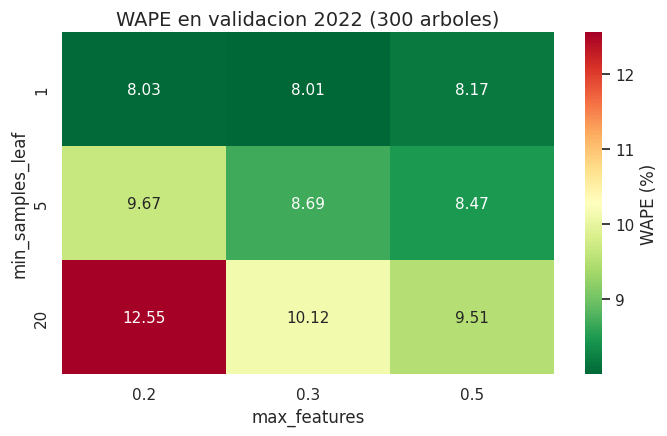

In [ ]:
# %%
# =========================================================
# PASO G2: Mapa de calor de hiperparametros (300 arboles)
# =========================================================
print("PASO G2: Mapa de calor de hiperparametros")
import seaborn as sns

p = pruebas[pruebas["n_estimators"] == 300]
tabla = p.pivot(index="min_samples_leaf", columns="max_features", values="WAPE_%")

plt.figure(figsize=(7, 4.5))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="RdYlGn_r", cbar_kws={"label": "WAPE (%)"})
plt.title("WAPE en validacion 2022 (300 arboles)")
plt.xlabel("max_features")
plt.ylabel("min_samples_leaf")
plt.tight_layout()
plt.show()


#importancia de las variables

In [ ]:
# %%
# =========================================================
# Importancia de las variables (4 principales + resto)
# Usa la serie "importancia" que creo el PASO M3
# =========================================================
print("PASO G6: Importancia de las variables")
NOMBRES = {"log_area_sembrada": "Area sembrada (log)",
           "log_area_disponible": "Area disponible (log)",
           "log_cosechada_ant": "Cosechada anio anterior (log)",
           "log_sembrada_ant": "Sembrada anio anterior (log)"}
top = importancia.head(4)
resto = importancia.iloc[4:].sum()
etiquetas = [NOMBRES.get(n, n) for n in top.index] + ["Las otras %d variables" % (len(importancia) - 4)]
valores = list(top.values) + [resto]

plt.figure(figsize=(10, 5))
barras = plt.barh(etiquetas[::-1], valores[::-1], color=[GRIS] + [VERDE] * 4)
plt.bar_label(barras, labels=[f"{v:.2f}" for v in valores[::-1]], padding=4, fontsize=12)
plt.title("Importancia: 4 variables concentran el %.0f %%" % (top.sum() * 100))
plt.xlabel("Importancia")
plt.xlim(0, max(valores) * 1.15)
plt.tight_layout()
plt.show()

PASO G6: Importancia de las variables


NameError: name 'importancia' is not defined

##RESULTADO POR AÑOS

PASO G3: Resultado global y por anio
                  Random Forest  Cosechada = sembrada  Disponible x tasa historica
2023                       8.68                 10.86                        13.70
2024                      10.36                 13.31                        14.84
2025                       9.69                 11.86                        14.14
Total\n2023-2025           9.57                 12.00                        14.22


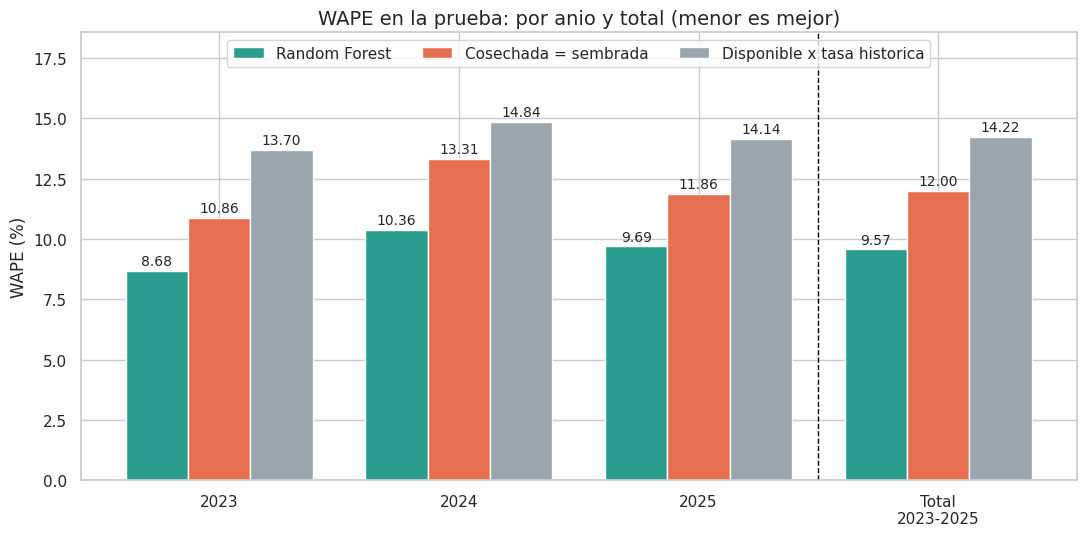

PASO G3: Ejecutado correctamente
-------------------------------


In [ ]:
# =========================================================
# PASO G3: Resultado global y por anio en UNA sola grafica
# Usa: predicciones, prueba, entreno_final, tasa_hist_completa (del bloque comun y M2)
# =========================================================
print("PASO G3: Resultado global y por anio")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VERDE = "#2a9d8f"
NARANJA = "#e76f51"
GRIS = "#9aa5ad"

real = predicciones["area_cosechada"].values
est_rf = predicciones["area_cosechada_estimada"].values
sembrada = predicciones["area_sembrada"].values
tasa = tasa_hist_completa(entreno_final, prueba)           # tasa historica (sale del entrenamiento)
est_tasa = (prueba["area_disponible"] * tasa).values       # regla: disponible x tasa historica
anios = predicciones["anio"].values

def wape(r, e):
    return np.abs(r - e).sum() / r.sum() * 100

grupos = ["2023", "2024", "2025", "Total\n2023-2025"]
mascaras = [anios == 2023, anios == 2024, anios == 2025, np.ones(len(anios), dtype=bool)]
tabla = pd.DataFrame({
    "Random Forest": [wape(real[m], est_rf[m]) for m in mascaras],
    "Cosechada = sembrada": [wape(real[m], sembrada[m]) for m in mascaras],
    "Disponible x tasa historica": [wape(real[m], est_tasa[m]) for m in mascaras]},
    index=grupos)
print(tabla.round(2).to_string())

x = np.arange(len(grupos))
ancho = 0.26
plt.figure(figsize=(11, 5.5))
for i, (nombre, color) in enumerate([("Random Forest", VERDE),
                                     ("Cosechada = sembrada", NARANJA),
                                     ("Disponible x tasa historica", GRIS)]):
    barras = plt.bar(x + (i - 1) * ancho, tabla[nombre], ancho, color=color, label=nombre)
    plt.bar_label(barras, fmt="%.2f", fontsize=10, padding=2)
plt.axvline(2.5, color="black", linestyle="--", linewidth=1)   # separa los anios del total
plt.xticks(x, grupos)
plt.ylabel("WAPE (%)")
plt.title("WAPE en la prueba: por anio y total (menor es mejor)")
plt.ylim(0, tabla.values.max() * 1.25)
plt.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.show()


## Mejora frente a la regla (area_sembrada = area_cosechada), por grupo

PASO G5: Mejora por grupo


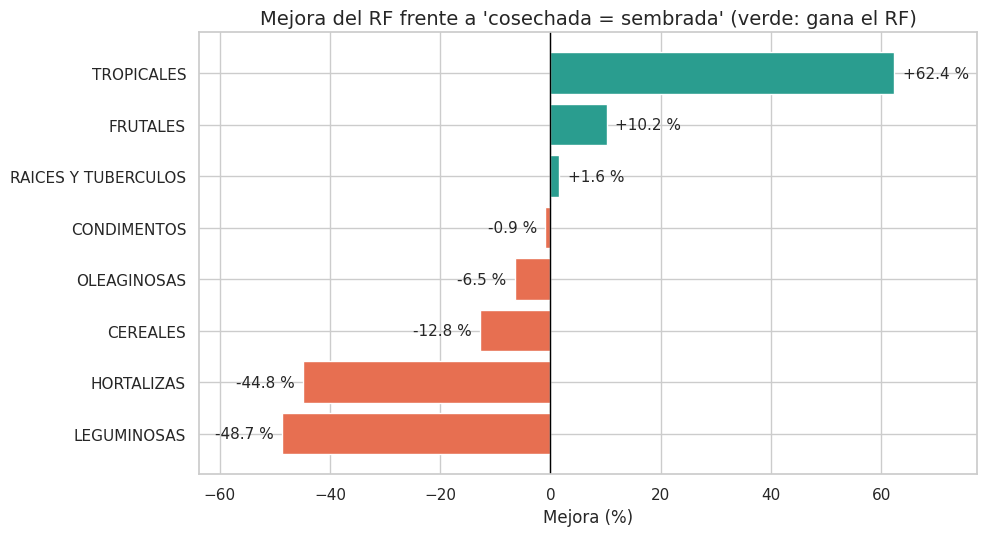

In [ ]:
# %%
# =========================================================
# Mejora frente a la regla, por grupo (barras divergentes)
# =========================================================
print("PASO G5: Mejora por grupo")
t = resultados[resultados["grupo"] != "TOTAL"].pivot(index="grupo", columns="modelo", values="WAPE_%")
mejora = (1 - t["Random Forest"] / t["Base: cosechada = sembrada"]) * 100
mejora = mejora.sort_values()
mejora.index = [corto(g) for g in mejora.index]

plt.figure(figsize=(10, 5.5))
colores = [VERDE if v > 0 else NARANJA for v in mejora.values]
plt.barh(mejora.index, mejora.values, color=colores)
for i, v in enumerate(mejora.values):
    plt.text(v + (1.5 if v >= 0 else -1.5), i, f"{v:+.1f} %", va="center",
             ha="left" if v >= 0 else "right", fontsize=11)
plt.axvline(0, color="black", linewidth=1)
plt.xlim(mejora.min() - 15, mejora.max() + 15)
plt.title("Mejora del RF frente a 'cosechada = sembrada' (verde: gana el RF)")
plt.xlabel("Mejora (%)")
plt.tight_layout()
plt.show()


PASO G10: Real vs estimada


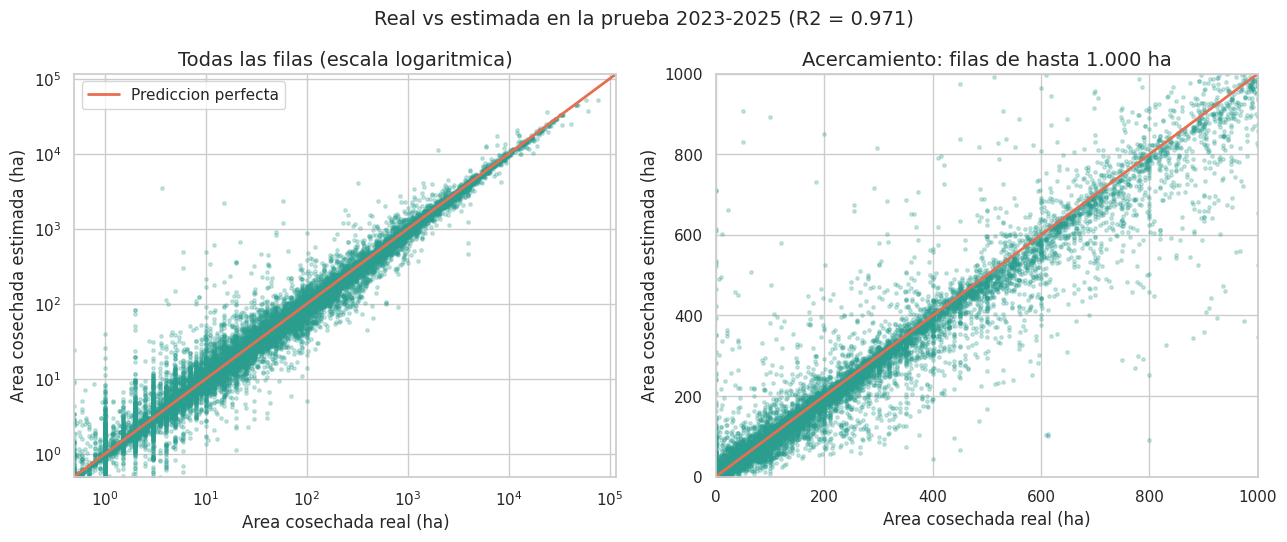

Filas en el acercamiento: 43443 de 46334


In [ ]:
# =========================================================
# Area cosechada real vs estimada (prueba 2023-2025)
# Usa la tabla "predicciones" que creo el PASO M2
# =========================================================
print("PASO G10: Real vs estimada")
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

VERDE = "#2a9d8f"
NARANJA = "#e76f51"

real = predicciones["area_cosechada"].values
estimada = predicciones["area_cosechada_estimada"].values

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5))

# Grafica 1: todas las filas, en escala logaritmica (las areas van de 0,5 a 100.000 ha)
ejes[0].scatter(real, estimada, s=6, alpha=0.25, color=VERDE)
limite = max(real.max(), estimada.max()) * 1.5
ejes[0].plot([0.5, limite], [0.5, limite], color=NARANJA, linewidth=2, label="Prediccion perfecta")
ejes[0].set_xscale("log")
ejes[0].set_yscale("log")
ejes[0].set_xlim(0.5, limite)
ejes[0].set_ylim(0.5, limite)
ejes[0].set_xlabel("Area cosechada real (ha)")
ejes[0].set_ylabel("Area cosechada estimada (ha)")
ejes[0].set_title("Todas las filas (escala logaritmica)")
ejes[0].legend(loc="upper left")

# Grafica 2: acercamiento a las filas pequenas y medianas (hasta 1.000 ha), escala normal
zoom = (real <= 1000) & (estimada <= 1000)
ejes[1].scatter(real[zoom], estimada[zoom], s=6, alpha=0.25, color=VERDE)
ejes[1].plot([0, 1000], [0, 1000], color=NARANJA, linewidth=2)
ejes[1].set_xlim(0, 1000)
ejes[1].set_ylim(0, 1000)
ejes[1].set_xlabel("Area cosechada real (ha)")
ejes[1].set_ylabel("Area cosechada estimada (ha)")
ejes[1].set_title("Acercamiento: filas de hasta 1.000 ha")

fig.suptitle("Real vs estimada en la prueba 2023-2025 (R2 = %.3f)" % r2_score(real, estimada), fontsize=14)
plt.tight_layout()
plt.show()
print("Filas en el acercamiento: %d de %d" % (zoom.sum(), len(real)))